# Student Performance Analysis

## Objective

Analyze students' academic performance using Python and Pandas to calculate subject-wise averages, validate the dataset, identify the top-performing students, and visualize performance patterns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
df = pd.read_csv("../data/StudentsPerformance.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
print("Columns:")
print(df.columns.tolist())

Columns:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [5]:
df.describe()

,math score,reading score,writing score
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00


In [6]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
score_columns = ["math score", "reading score", "writing score"]

print("Missing scores:")
print(df[score_columns].isnull().sum())

print("\nNegative scores:")
print((df[score_columns] < 0).sum())

print("\nScores outside valid range (0-100):")
print(((df[score_columns] < 0) | (df[score_columns] > 100)).sum())

Missing scores:
math score       0
reading score    0
writing score    0
dtype: int64

Negative scores:
math score       0
reading score    0
writing score    0
dtype: int64

Scores outside valid range (0-100):
math score       0
reading score    0
writing score    0
dtype: int64


In [9]:
print("Data validation completed.")

Data validation completed.


In [10]:
print(df.shape)
print(df.columns.tolist())
print(df[score_columns].isnull().sum())
print((df[score_columns] < 0).sum())
print(((df[score_columns] < 0) | (df[score_columns] > 100)).sum())

(1000, 8)
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']
math score       0
reading score    0
writing score    0
dtype: int64
math score       0
reading score    0
writing score    0
dtype: int64
math score       0
reading score    0
writing score    0
dtype: int64


## Subject-wise Performance

Calculate the average marks obtained in Mathematics, Reading, and Writing.

In [11]:
score_columns = ["math score", "reading score", "writing score"]

subject_averages = df[score_columns].mean()

print("Average Marks by Subject:")
print(subject_averages)

Average Marks by Subject:
math score      66.09
reading score   69.17
writing score   68.05
dtype: float64


In [12]:
df["average_score"] = df[score_columns].mean(axis=1)

df[["math score", "reading score", "writing score", "average_score"]].head()

,math score,reading score,writing score,average_score
0,72,72,74,72.67
1,69,90,88,82.33
2,90,95,93,92.67
3,47,57,44,49.33
4,76,78,75,76.33


In [13]:
top_5_students = (
    df.sort_values("average_score", ascending=False)
      .head(5)
)

top_5_students[
    ["gender", "math score", "reading score", "writing score", "average_score"]
]

,gender,math score,reading score,writing score,average_score
916,male,100,100,100,100.00
962,female,100,100,100,100.00
458,female,100,100,100,100.00
114,female,99,100,100,99.67
712,female,98,100,99,99.00


In [14]:
top_5_display = top_5_students[
    ["gender", "race/ethnicity", "math score", "reading score",
     "writing score", "average_score"]
].copy()

top_5_display

,gender,race/ethnicity,math score,reading score,writing score,average_score
916,male,group E,100,100,100,100.00
962,female,group E,100,100,100,100.00
458,female,group E,100,100,100,100.00
114,female,group E,99,100,100,99.67
712,female,group D,98,100,99,99.00


In [15]:
highest_average = df["average_score"].max()
lowest_average = df["average_score"].min()

print(f"Highest Overall Average: {highest_average:.2f}")
print(f"Lowest Overall Average: {lowest_average:.2f}")

Highest Overall Average: 100.00
Lowest Overall Average: 9.00


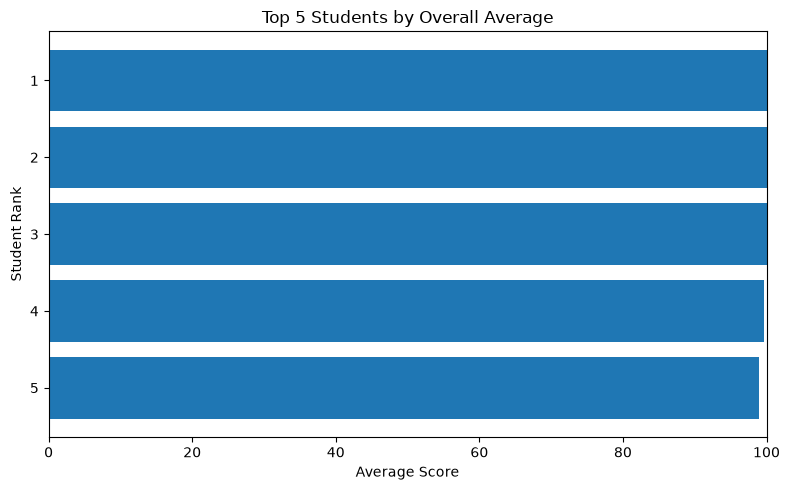

In [18]:
# Create a clean Top 5 ranking table
top_5_chart = top_5_students[
    ["math score", "reading score", "writing score", "average_score"]
].copy()

top_5_chart = top_5_chart.sort_values("average_score", ascending=True)

# Assign display ranks
top_5_chart["rank"] = range(5, 0, -1)

plt.figure(figsize=(8, 5))

plt.barh(
    top_5_chart["rank"].astype(str),
    top_5_chart["average_score"]
)

plt.title("Top 5 Students by Overall Average")
plt.xlabel("Average Score")
plt.ylabel("Student Rank")
plt.xlim(0, 100)

plt.tight_layout()

plt.savefig("../visuals/top_5_students.png", dpi=300)
plt.show()

In [19]:
top_5_display = top_5_students[
    [
        "gender",
        "race/ethnicity",
        "math score",
        "reading score",
        "writing score",
        "average_score"
    ]
].copy()

top_5_display

,gender,race/ethnicity,math score,reading score,writing score,average_score
916,male,group E,100,100,100,100.00
962,female,group E,100,100,100,100.00
458,female,group E,100,100,100,100.00
114,female,group E,99,100,100,99.67
712,female,group D,98,100,99,99.00


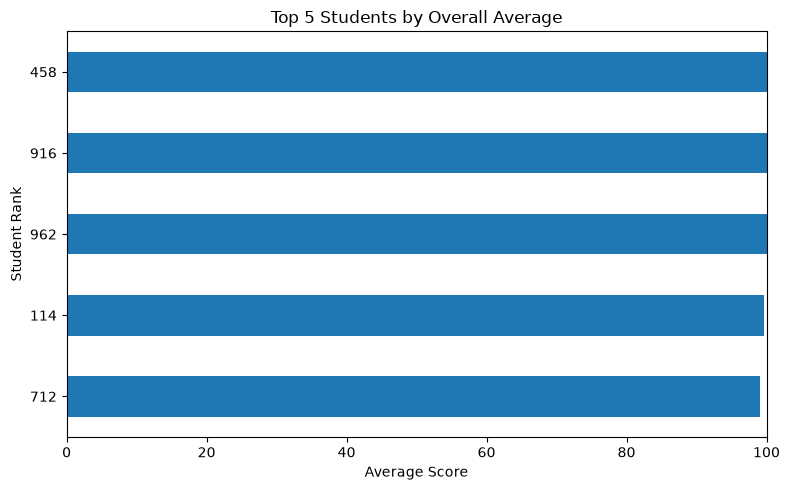

In [20]:
plt.figure(figsize=(8, 5))

top_5_chart = top_5_students["average_score"].sort_values()

top_5_chart.plot(kind="barh")

plt.title("Top 5 Students by Overall Average")
plt.xlabel("Average Score")
plt.ylabel("Student Rank")
plt.xlim(0, 100)
plt.tight_layout()

plt.savefig("../visuals/top_5_students.png", dpi=300)
plt.show()

## Score Distribution

Examine how student scores are distributed across Mathematics, Reading, and Writing.

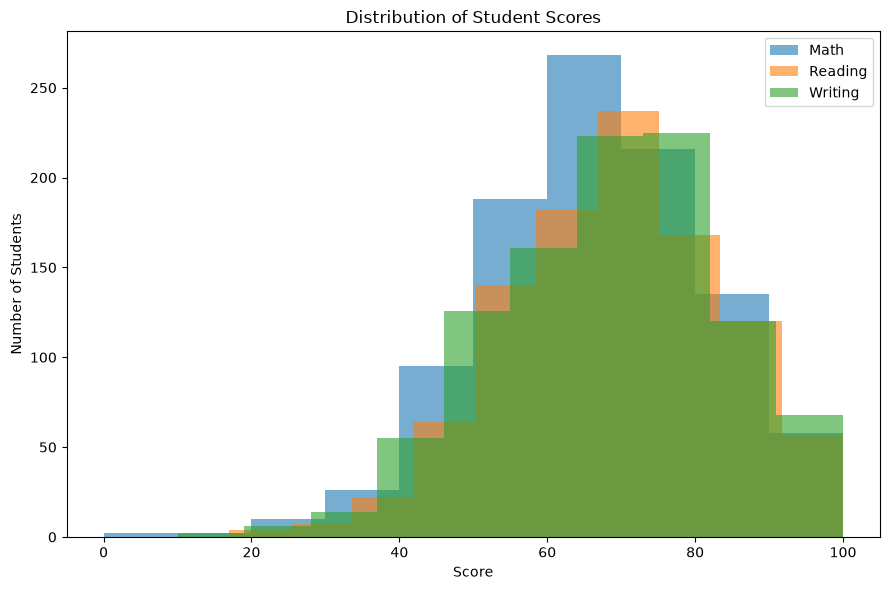

In [21]:
plt.figure(figsize=(9, 6))

plt.hist(df["math score"], bins=10, alpha=0.6, label="Math")
plt.hist(df["reading score"], bins=10, alpha=0.6, label="Reading")
plt.hist(df["writing score"], bins=10, alpha=0.6, label="Writing")

plt.title("Distribution of Student Scores")
plt.xlabel("Score")
plt.ylabel("Number of Students")
plt.legend()
plt.tight_layout()

plt.savefig("../visuals/score_distribution.png", dpi=300)
plt.show()

In [22]:
prep_performance = df.groupby("test preparation course")[score_columns].mean()

print("Average Scores by Test Preparation Course:")
print(prep_performance)

Average Scores by Test Preparation Course:
                         math score  reading score  writing score
test preparation course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50


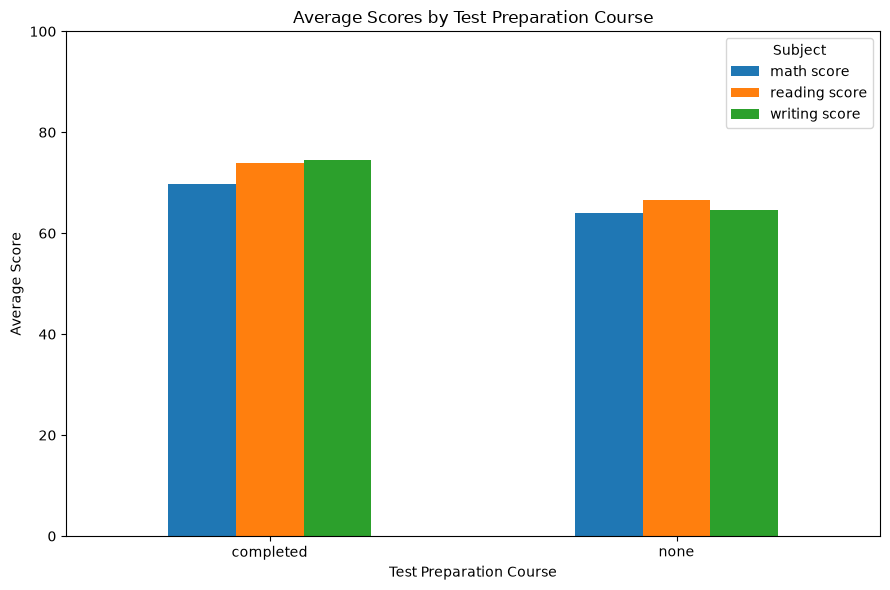

In [23]:
prep_performance.plot(kind="bar", figsize=(9, 6))

plt.title("Average Scores by Test Preparation Course")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()

plt.savefig("../visuals/test_preparation_performance.png", dpi=300)
plt.show()

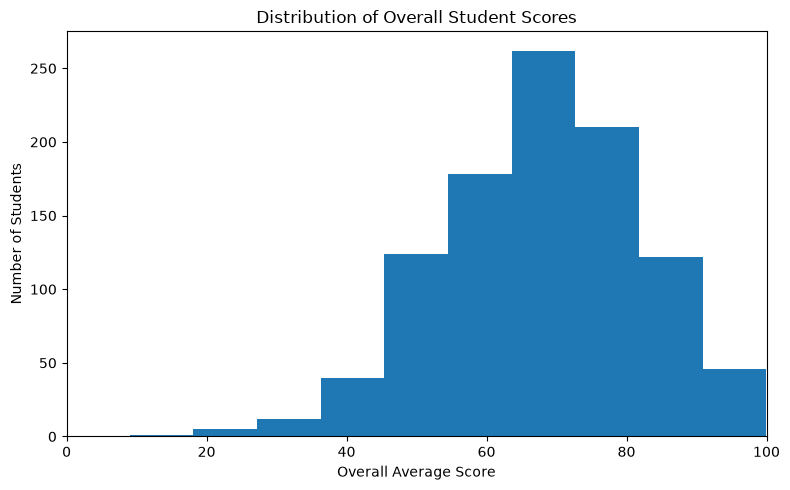

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(df["average_score"], bins=10)

plt.title("Distribution of Overall Student Scores")
plt.xlabel("Overall Average Score")
plt.ylabel("Number of Students")
plt.xlim(0, 100)
plt.tight_layout()

plt.savefig("../visuals/overall_score_distribution.png", dpi=300)
plt.show()

In [25]:
print(prep_performance.round(2))

                         math score  reading score  writing score
test preparation course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50


In [26]:
print(df["test preparation course"].value_counts())

test preparation course
none         642
completed    358
Name: count, dtype: int64


In [27]:
print(prep_performance.round(2))

                         math score  reading score  writing score
test preparation course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50


In [28]:
print(df["test preparation course"].value_counts())

test preparation course
none         642
completed    358
Name: count, dtype: int64


## Key Business Insights

1. **Reading has the highest average score:** Reading has the highest subject average at 69.17, followed by Writing at 68.05 and Mathematics at 66.09.

2. **Mathematics is the lowest-performing subject:** Mathematics has the lowest average score of 66.09, indicating that it may require greater academic support.

3. **Strongest overall performers:** The top three students achieved a perfect overall average of 100.00 across Mathematics, Reading, and Writing.

4. **Test preparation is associated with higher performance:** Students who completed the test preparation course achieved higher average scores in all three subjects compared with students who did not complete it.

5. **Test preparation group comparison:** 358 students completed the preparation course, while 642 students did not.

6. **Score concentration:** Most students have overall average scores concentrated in the middle-to-upper range, with relatively few students at the extreme low end.

7. **Top-performing records:** The highest-performing students were predominantly from Group E, with four of the five top records belonging to this group.

## Recommendations

1. **Strengthen Mathematics support:** Since Mathematics has the lowest subject average, additional practice sessions, tutoring, and targeted problem-solving activities could help improve performance.

2. **Encourage test preparation:** The completed preparation group performs better across all three subjects. Students should therefore be encouraged to complete available preparation programs before examinations.

3. **Maintain Reading and Writing performance:** Reading and Writing show relatively higher average scores, so existing learning strategies in these subjects should be maintained.

4. **Identify students requiring additional support:** Students with lower overall averages can be identified using the score distribution and provided with targeted academic assistance.

5. **Use performance tracking:** Subject-wise averages and overall scores can be monitored regularly to identify changes in academic performance.

## Conclusion

The Student Performance Analysis successfully evaluated 1,000 student records using Python and Pandas. The dataset was validated for missing values, negative scores, and invalid marks, with no issues found.

Reading recorded the highest average score at 69.17, while Mathematics recorded the lowest at 66.09. The analysis also identified the top five performing student records based on their overall average across the three subjects.

Students who completed the test preparation course achieved higher average scores in Mathematics, Reading, and Writing than those who did not complete the course. The visualizations further highlighted subject-wise performance, score distributions, overall performance, and the relationship between test preparation and academic results.

Overall, the analysis demonstrates how basic data cleaning, statistical analysis, and visualization can be used to derive meaningful insights from student performance data.

In [29]:
print("===== DATA VALIDATION SUMMARY =====")
print(f"Total Students: {len(df)}")
print(f"Missing Score Values: {df[score_columns].isnull().sum().sum()}")
print(f"Negative Score Values: {(df[score_columns] < 0).sum().sum()}")
print(f"Invalid Score Values: {((df[score_columns] < 0) | (df[score_columns] > 100)).sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")

print("\n===== SUBJECT AVERAGES =====")
for subject, average in subject_averages.items():
    print(f"{subject}: {average:.2f}")

print("\n===== TOP 5 OVERALL AVERAGES =====")
print(top_5_students["average_score"].round(2).to_string(index=False))

===== DATA VALIDATION SUMMARY =====
Total Students: 1000
Missing Score Values: 0
Negative Score Values: 0
Invalid Score Values: 0
Duplicate Rows: 0

===== SUBJECT AVERAGES =====
math score: 66.09
reading score: 69.17
writing score: 68.05

===== TOP 5 OVERALL AVERAGES =====
100.00
100.00
100.00
 99.67
 99.00
